# Week 5: Support Vector Machines, the Kernel Trick and Regularization
Eric Benaroch, Module C Capstone

Research question from my proposal: does malicious behavior leave the same statistical pattern in different threat domains, or is every domain different?

Same datasets and task as Week 4: predict whether a flow (CICAndMal2017, CICIDS2017) or an article (WELFake) is malicious (1) or benign (0).

Plan:
1. Show the lesson's idea of a margin and support vectors on a small example.
2. Check the kernel trick by hand: polynomial kernel in 3 and 2 dimensions, and the Gaussian kernel.
3. See how linear, polynomial and Gaussian (RBF) kernels draw boundaries on two real features.
4. Fit SVMs on all features and compare them with Week 4's logistic regression.
5. Show why feature scaling matters for an SVM.
6. Tune the regularization parameter C (and the RBF width) with cross-validation.
7. Use the margin to compare how separable malicious and benign data are in each domain.

Kernel SVMs get slow on large data (the work grows faster than the number of rows), so the kernel models are trained on a 10,000-row sample of each training set and tested on 20,000 test rows.

## 1. Setup

In [3]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, GroupShuffleSplit, validation_curve
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.metrics.pairwise import polynomial_kernel, rbf_kernel
import warnings
warnings.filterwarnings("ignore")

import os
from pathlib import Path
DATA_DIR = Path(os.environ.get("CAPSTONE_DATA_DIR", "."))   # folder with the zips and the WELFake csv
FIG_DIR = Path("figures_week5"); FIG_DIR.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

## 2. Margin and support vectors
A small made-up example like the lesson's Figure 1: two groups of points, a linear SVM with a large C (so it tries to classify every point correctly), the decision boundary, the two margin lines and the support vectors. For a linear SVM the margin on each side is 1 / ||w||, where w is the vector of coefficients.

margin = 1.016
closest blue point = 1.016, closest yellow point = 1.016
number of support vectors: 2


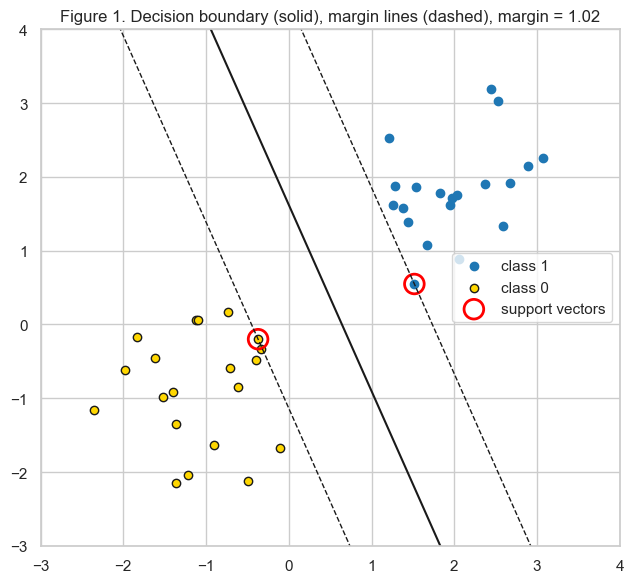

In [5]:
rng = np.random.RandomState(3)
blue = rng.normal([2, 2], 0.6, size=(20, 2))
yellow = rng.normal([-1, -1], 0.6, size=(20, 2))
X_toy = np.vstack([blue, yellow]); y_toy = np.array([1] * 20 + [0] * 20)

svm_toy = SVC(kernel="linear", C=1000).fit(X_toy, y_toy)
w, b = svm_toy.coef_[0], svm_toy.intercept_[0]
margin = 1 / np.linalg.norm(w)

dist = (X_toy @ w + b) / np.linalg.norm(w)        # signed distance of every point to the boundary
print(f"margin = {margin:.3f}")
print(f"closest blue point = {dist[y_toy == 1].min():.3f}, closest yellow point = {-dist[y_toy == 0].max():.3f}")
print("number of support vectors:", len(svm_toy.support_))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(blue[:, 0], blue[:, 1], color="tab:blue", label="class 1")
ax.scatter(yellow[:, 0], yellow[:, 1], color="gold", edgecolor="k", label="class 0")
xx = np.linspace(-3, 4, 100)
for offset, style in [(0, "-"), (1, "--"), (-1, "--")]:
    ax.plot(xx, (offset - b - w[0] * xx) / w[1], "k" + style, lw=1.5 if offset == 0 else 1)
sv = svm_toy.support_vectors_
ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolor="none", edgecolor="red", lw=2, label="support vectors")
ax.set_xlim(-3, 4); ax.set_ylim(-3, 4); ax.legend()
ax.set_title(f"Figure 1. Decision boundary (solid), margin lines (dashed), margin = {margin:.2f}")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_margin.png", dpi=150); plt.show()

The SVM found a boundary with a margin of 1.016, and the closest point on each side is exactly 1.016 away. Only 2 of the 40 points are support vectors (circled in red). The boundary depends only on these points, so moving any other point (without crossing the margin) would not change it.

This also answers Think About It question 1. The margin is always equal on both sides. If one side had more room, the hyperplane could be moved toward that side, which would make the smaller margin bigger. So the best hyperplane always sits exactly in the middle.

## 3. The kernel trick by hand
### 3a. Polynomial kernel, dimension 3 (the lesson's example)
The kernel (x.z)^2 should equal the ordinary inner product of the 9-dimensional vectors Vec(x) = (x1x1, x1x2, x1x3, x2x1, ..., x3x3) and Vec(z).

In [8]:
def vec3(v):
    return np.array([v[i] * v[j] for i in range(3) for j in range(3)])

x = np.array([1.0, 2.0, 3.0]); z = np.array([0.5, -1.0, 2.0])
print("(x.z)^2 =", (x @ z) ** 2)
print("Vec(x).Vec(z) =", vec3(x) @ vec3(z))
print("sklearn polynomial_kernel (degree 2, c = 0) =", polynomial_kernel([x], [z], degree=2, gamma=1, coef0=0)[0, 0])

(x.z)^2 = 20.25
Vec(x).Vec(z) = 20.25
sklearn polynomial_kernel (degree 2, c = 0) = 20.25


### 3b. Polynomial kernel, dimension 2 (Think About It question 2)
For x = (x1, x2) and c = 0, (x.z)^2 = (x1z1 + x2z2)^2 = x1^2 z1^2 + 2 x1x2 z1z2 + x2^2 z2^2. This is the inner product of Vec(x) = (x1^2, x1x2, x2x1, x2^2), or written with 3 terms, (x1^2, sqrt(2) x1x2, x2^2). Checking on random vectors:

In [10]:
def vec2(v):
    return np.array([v[0] ** 2, np.sqrt(2) * v[0] * v[1], v[1] ** 2])

for _ in range(3):
    x, z = np.random.randn(2), np.random.randn(2)
    print(f"(x.z)^2 = {(x @ z) ** 2:.6f}   Vec(x).Vec(z) = {vec2(x) @ vec2(z):.6f}")

(x.z)^2 = 0.012808   Vec(x).Vec(z) = 0.012808
(x.z)^2 = 2.255606   Vec(x).Vec(z) = 2.255606
(x.z)^2 = 0.000049   Vec(x).Vec(z) = 0.000049


### 3c. Gaussian kernel (Think About It question 3)
K(x, z) = exp(-||x - z||^2 / (2 sigma^2)). Two quick checks show it is not just x.z:
- K(x, x) is always 1, but x.x = ||x||^2 changes with the length of x.
- Scaling x by 10 changes x.z by a factor of 10, but changes K in a completely different way.

The matrix of K values is still positive semi-definite (no negative eigenvalues), which is what "close enough to an inner product" means in practice.

In [12]:
pts = np.random.RandomState(0).randn(6, 2)
K = rbf_kernel(pts, pts, gamma=0.5)          # gamma = 1 / (2 sigma^2), here sigma = 1
print("K(x, x) for every point:", np.diag(K).round(3))
print("x.x for the same points:", (pts ** 2).sum(axis=1).round(3))
x, z = pts[0], pts[1]
print(f"x.z = {x @ z:.3f}, (10x).z = {(10 * x) @ z:.3f}")
print(f"K(x, z) = {rbf_kernel([x], [z], gamma=0.5)[0, 0]:.4f}, K(10x, z) = {rbf_kernel([10 * x], [z], gamma=0.5)[0, 0]:.2e}")
print("smallest eigenvalue of the kernel matrix:", np.linalg.eigvalsh(K).min().round(4))

K(x, x) for every point: [1. 1. 1. 1. 1. 1.]
x.x for the same points: [3.272 5.98  4.443 0.926 0.179 2.136]
x.z = 2.623, (10x).z = 26.233
K(x, z) = 0.1350, K(10x, z) = 1.11e-61
smallest eigenvalue of the kernel matrix: 0.2024


## 4. Load the data
Same data and cleaning as Weeks 1 to 4.

In [14]:
COLS = {"Flow Duration": "dur", "Total Fwd Packets": "fwd_pkts", "Total Backward Packets": "bwd_pkts",
        "Fwd Packet Length Mean": "fwd_len", "Bwd Packet Length Mean": "bwd_len",
        "Flow IAT Mean": "iat", "Flow Bytes/s": "bytes_s", "Label": "label"}

def read_zip(zip_name):
    frames = []
    with zipfile.ZipFile(DATA_DIR / zip_name) as z:
        for name in z.namelist():
            if name.endswith(".csv"):
                df = pd.read_csv(z.open(name), skipinitialspace=True, encoding="latin1",
                                 usecols=lambda c: c.strip() in COLS)
                df.columns = df.columns.str.strip()
                df["file"] = name
                frames.append(df)
    return pd.concat(frames, ignore_index=True).rename(columns=COLS)

mal_parts = []
for cat in ["Benign", "Adware", "Ransomware", "Scareware", "SMSmalware"]:
    df = read_zip(f"{cat}-CSVs.zip")
    df["category"] = cat
    mal_parts.append(df)
    print(cat, len(df), "flows from", df["file"].nunique(), "capture files")
mal_raw = pd.concat(mal_parts, ignore_index=True)

ids_raw = read_zip("MachineLearningCSV.zip")
print("CICIDS2017", len(ids_raw))

Benign 1205515 flows from 1700 capture files
Adware 424147 flows from 104 capture files
Ransomware 348943 flows from 101 capture files
Scareware 400841 flows from 112 capture files
SMSmalware 237133 flows from 109 capture files
CICIDS2017 2830743


Ransomware 348943 flows from 101 capture files


Scareware 400841 flows from 112 capture files


SMSmalware 237133 flows from 109 capture files


CICIDS2017 2830743


In [15]:
wel_raw = pd.read_csv(next(DATA_DIR.glob("WELFake*.csv")))      # finds WELFake_Dataset.csv
print(wel_raw.shape)
print(wel_raw["label"].value_counts())

# Which label is fake? Real news in WELFake is mostly Reuters wire copy.
print(wel_raw.groupby("label")["text"].apply(lambda s: s.str.contains("(Reuters)", regex=False).mean()))

(72134, 4)
label
1    37106
0    35028
Name: count, dtype: int64
label
0   0.607
1   0.000
Name: text, dtype: float64


The dataset card says label 1 means real, but in this file label 0 has the Reuters articles (about 61%) and label 1 has almost none. So label 1 is treated as fake (malicious = 1).

## 5. Clean and prepare
Network data: remove infinite and missing values, negative values, zero-length flows and duplicates, as in Module B. All flow features are very skewed (a few huge flows), so I take log1p of every feature and the target. I take a random sample so the models run quickly: 60,000 flows per CICAndMal2017 category, and 150,000 benign plus 150,000 attack flows for CICIDS2017.

WELFake: drop empty articles and duplicates, then make simple numeric features from the title and text.

In [18]:
def clean_flows(df):
    num = list(COLS.values())[:-1]
    df = df.copy()
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df[(df[num] >= 0).all(axis=1) & (df["dur"] > 0)].drop_duplicates()
    for c in num:
        df[c] = np.log1p(df[c])
    return df.rename(columns={"bytes_s": "y"})

mal = clean_flows(mal_raw)
mal["malicious"] = (mal["category"] != "Benign").astype(int)
mal = mal.groupby("category").sample(60000, random_state=SEED)

def attack_group(label):
    label = label.upper()
    if label == "BENIGN": return "Benign"
    if "DOS" in label: return "DoS/DDoS"
    if "PATATOR" in label: return "BruteForce"
    if "WEB ATTACK" in label: return "WebAttack"
    if "PORTSCAN" in label: return "PortScan"
    return "Other"

ids = clean_flows(ids_raw)
ids["category"] = ids["label"].map(attack_group)
ids["malicious"] = (ids["category"] != "Benign").astype(int)
ids = ids.groupby("malicious").sample(150000, random_state=SEED)

print(mal["category"].value_counts(), "\n")
print(ids["category"].value_counts())

category
Adware        60000
Benign        60000
Ransomware    60000
SMSmalware    60000
Scareware     60000
Name: count, dtype: int64 

category
Benign        150000
DoS/DDoS      144313
BruteForce      3343
WebAttack        982
PortScan         740
Other            622
Name: count, dtype: int64


In [19]:
wel = wel_raw.dropna(subset=["text"]).fillna({"title": ""}).drop_duplicates(subset=["title", "text"])
wel = wel[wel["text"].str.split().str.len() > 0].copy()
wel["malicious"] = wel["label"]                                   # 1 = fake
wel["y"] = np.log1p(wel["text"].str.split().str.len())            # target: log word count
wel["title_words"] = np.log1p(wel["title"].str.split().str.len())
wel["title_chars"] = np.log1p(wel["title"].str.len())
wel["title_caps"] = wel["title"].str.count(r"[A-Z]") / wel["title"].str.len().clip(lower=1)   # share of capital letters
wel["exclaim"] = np.log1p(wel["title"].str.count("!") + wel["text"].str.count("!"))
wel["avg_word_len"] = wel["text"].str.len() / wel["text"].str.split().str.len()
wel["avg_word_len"] = wel["avg_word_len"].clip(upper=wel["avg_word_len"].quantile(0.99))
print(len(wel), "articles, fake share =", round(wel["malicious"].mean(), 2))

63110 articles, fake share = 0.45


## 6. Features for classification
The target is now the malicious label. Throughput (Flow Bytes/s) and word count, which were the targets in Weeks 1 to 3, become features. All features are already on a log scale except title_caps and avg_word_len.

In [21]:
mal = mal.rename(columns={"y": "bytes_s"})
ids = ids.rename(columns={"y": "bytes_s"})
wel = wel.rename(columns={"y": "word_count"})

NET = ["dur", "fwd_pkts", "bwd_pkts", "fwd_len", "bwd_len", "iat", "bytes_s"]
WEL = ["title_words", "title_chars", "title_caps", "exclaim", "avg_word_len", "word_count"]
DATA = {"CICAndMal2017": (mal, NET), "CICIDS2017": (ids, NET), "WELFake": (wel, WEL)}

SPLITS = {}
for name, (df, feats) in DATA.items():
    train, test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["malicious"])
    small = train.sample(10000, random_state=SEED)                 # training sample for kernel SVMs
    test_s = test.sample(20000, random_state=SEED) if len(test) > 20000 else test
    scaler = StandardScaler().fit(train[feats])
    SPLITS[name] = {"X_train": scaler.transform(train[feats]), "y_train": train["malicious"].values,
                    "X_small": scaler.transform(small[feats]), "y_small": small["malicious"].values,
                    "X_test": scaler.transform(test_s[feats]), "y_test": test_s["malicious"].values,
                    "raw_small": small[feats], "raw_test": test_s[feats], "feats": feats,
                    "train": train, "test": test_s}
    print(f"{name}: full train {len(train)}, SVM train sample {len(small)}, test {len(test_s)}")

CICAndMal2017: full train 240000, SVM train sample 10000, test 20000
CICIDS2017: full train 240000, SVM train sample 10000, test 20000
WELFake: full train 50488, SVM train sample 10000, test 12622


## 7. How each kernel draws the boundary
To see the boundary, I use only two features per dataset and 2,000 points: forward packet length and inter-arrival time for the network data, and title capitals and title words for WELFake. The linear kernel can only draw a straight line. The polynomial (degree 3) and Gaussian (RBF) kernels draw curves, as the lesson describes.

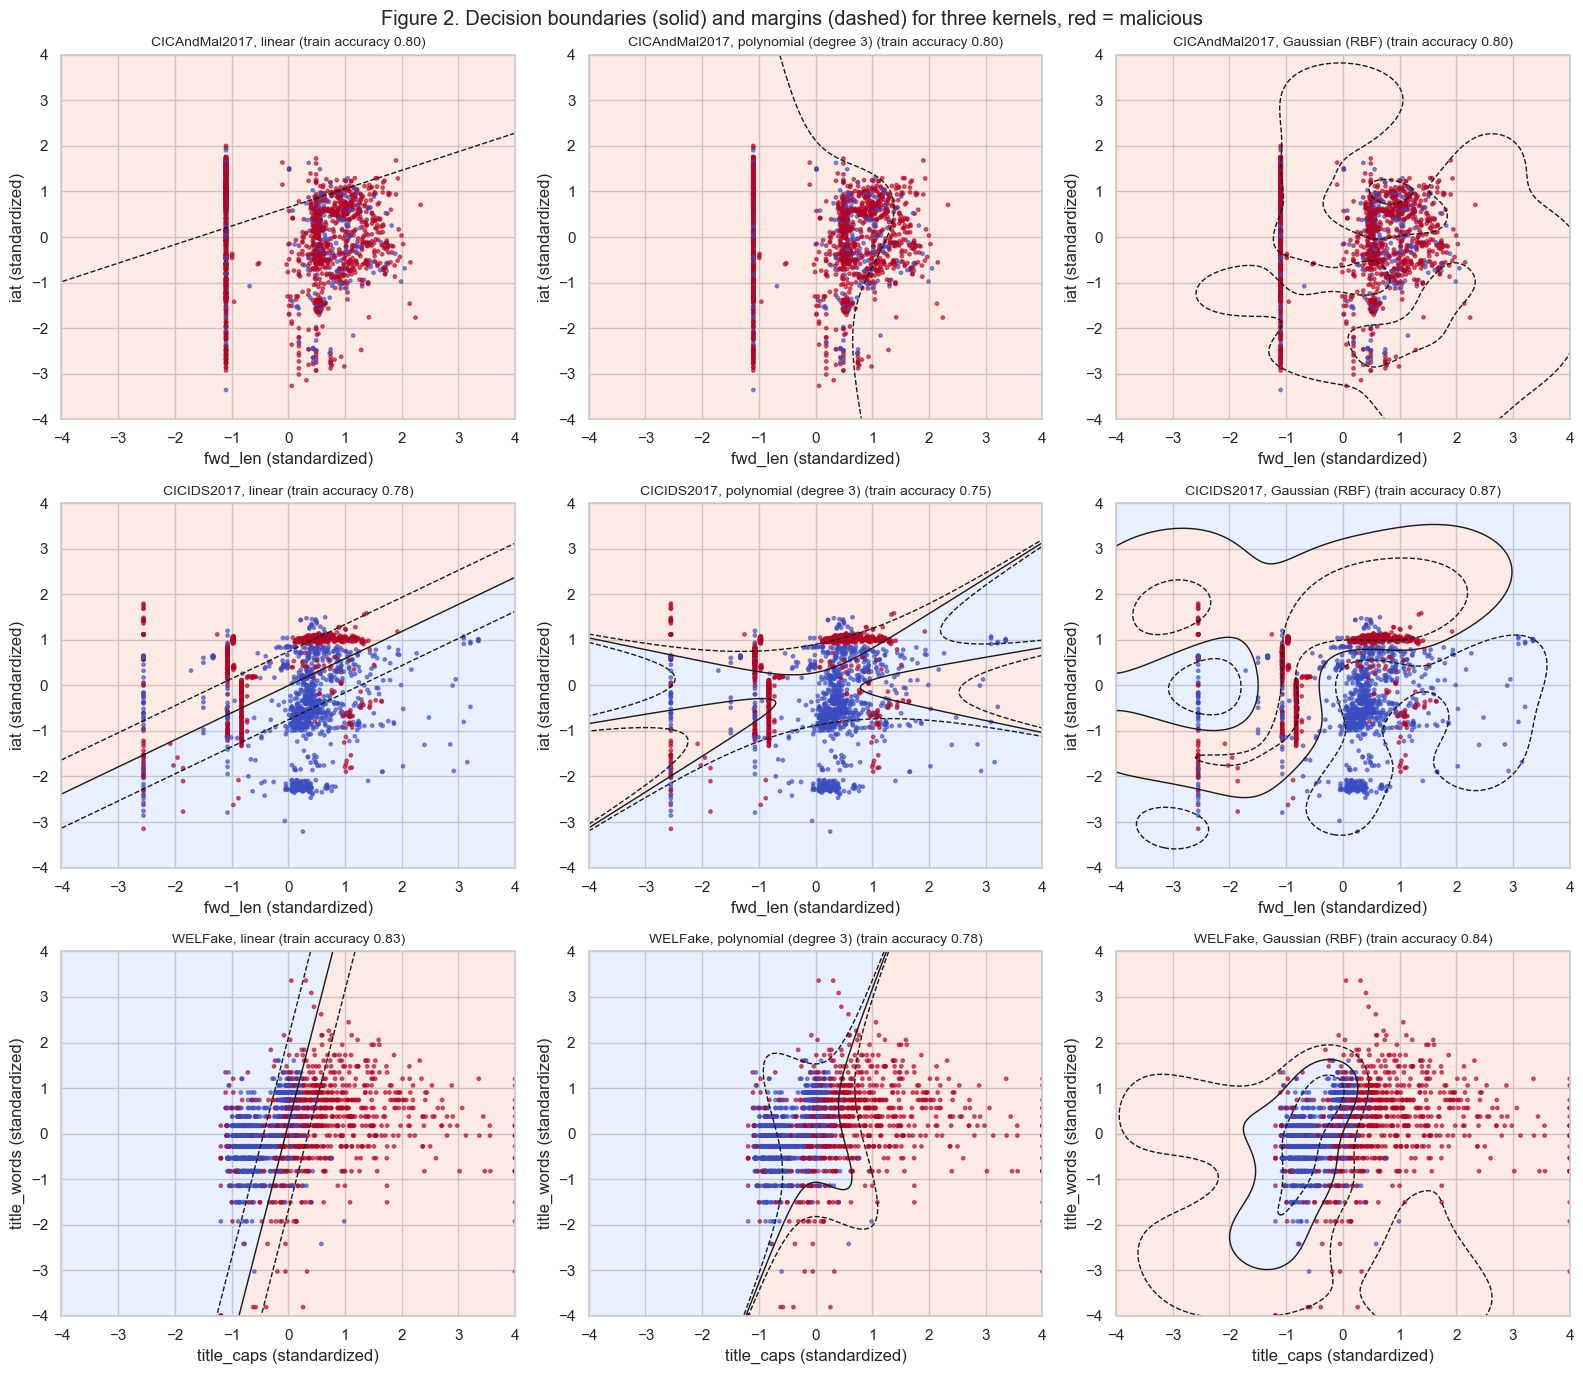

In [23]:
PAIR = {"CICAndMal2017": ["fwd_len", "iat"], "CICIDS2017": ["fwd_len", "iat"], "WELFake": ["title_caps", "title_words"]}
KERNELS = [("linear", SVC(kernel="linear", C=1)), ("polynomial (degree 3)", SVC(kernel="poly", degree=3, C=1)), ("Gaussian (RBF)", SVC(kernel="rbf", C=1))]

fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for i, (name, s) in enumerate(SPLITS.items()):
    cols = [s["feats"].index(f) for f in PAIR[name]]
    X2, y2 = s["X_small"][:2000][:, cols], s["y_small"][:2000]
    X2 = np.clip(X2, -4, 4)
    gx, gy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-4, 4, 200))
    for j, (label, model) in enumerate(KERNELS):
        model.fit(X2, y2)
        Z = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
        ax = axes[i, j]
        ax.contourf(gx, gy, Z > 0, alpha=0.2, cmap="coolwarm")
        ax.contour(gx, gy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=1)
        ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", s=6, alpha=0.6)
        acc = accuracy_score(y2, model.predict(X2))
        ax.set_title(f"{name}, {label} (train accuracy {acc:.2f})", fontsize=10)
        ax.set_xlabel(PAIR[name][0] + " (standardized)"); ax.set_ylabel(PAIR[name][1] + " (standardized)")
fig.suptitle("Figure 2. Decision boundaries (solid) and margins (dashed) for three kernels, red = malicious")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_kernels.png", dpi=150); plt.show()

What Figure 2 shows:
- CICAndMal2017: every kernel labels the whole plane as malicious (train accuracy 0.80, which is just the share of malware). Malware and benign flows sit on top of each other, so no line or curve can separate them.
- CICIDS2017: the linear kernel can only draw a slanted line (accuracy 0.78). The Gaussian kernel draws closed curves around the groups of attack flows and reaches 0.87 with only two features. This is the lesson's point: a flat hyperplane in the kernel's higher-dimensional space becomes a curved boundary in the original space.
- WELFake: fake articles (more capital letters in the title) are mostly to the right. The Gaussian kernel wraps a curve around the dense group of real articles (0.84).
- The polynomial kernel is the least stable: its boundaries shoot off to the edges of the plot and its accuracy is lower than linear in two datasets.

## 8. SVMs on all features
The models:
- logistic regression on the same 10,000 rows, as the Week 4 baseline
- linear SVM on the same 10,000 rows, and also on the full training set (LinearSVC is fast enough for that)
- polynomial and Gaussian kernel SVMs on the 10,000 rows

The lesson notes that a basic SVM gives a class, not a probability. For ROC AUC I use the SVM's decision function (the signed distance to the boundary) as the score.

In [26]:
def scores(y, pred, score):
    return {"accuracy": accuracy_score(y, pred), "macro F1": f1_score(y, pred, average="macro"), "ROC AUC": roc_auc_score(y, score)}

results = []
for name, s in SPLITS.items():
    models = [("Logistic (10k rows)", LogisticRegression(max_iter=2000), "small"),
              ("Linear SVM (10k rows)", LinearSVC(C=1), "small"),
              ("Linear SVM (all rows)", LinearSVC(C=1), "full"),
              ("Polynomial SVM (10k rows)", SVC(kernel="poly", degree=3, C=1), "small"),
              ("Gaussian SVM (10k rows)", SVC(kernel="rbf", C=1), "small")]
    for label, model, rows in models:
        X, y = (s["X_small"], s["y_small"]) if rows == "small" else (s["X_train"], s["y_train"])
        model.fit(X, y)
        score = model.decision_function(s["X_test"])
        results.append({"dataset": name, "model": label, **scores(s["y_test"], model.predict(s["X_test"]), score)})
pd.DataFrame(results).pivot(index="model", columns="dataset", values=["macro F1", "ROC AUC"]).round(3)

macro F1                          ROC AUC  \
dataset                   CICAndMal2017 CICIDS2017 WELFake CICAndMal2017   
model                                                                      
Gaussian SVM (10k rows)           0.443      0.978   0.866         0.532   
Linear SVM (10k rows)             0.443      0.895   0.828         0.527   
Linear SVM (all rows)             0.443      0.897   0.828         0.533   
Logistic (10k rows)               0.443      0.894   0.828         0.530   
Polynomial SVM (10k rows)         0.443      0.945   0.795         0.475   

                                              
dataset                   CICIDS2017 WELFake  
model                                         
Gaussian SVM (10k rows)        0.994   0.936  
Linear SVM (10k rows)          0.949   0.896  
Linear SVM (all rows)          0.950   0.896  
Logistic (10k rows)            0.941   0.896  
Polynomial SVM (10k rows)      0.960   0.896

Results with all features:
- The linear SVM gives almost the same results as logistic regression (CICIDS2017 macro F1 0.895 vs 0.894; WELFake 0.828 vs 0.828), as the lesson says. Using all 240,000 rows instead of 10,000 barely changes it.
- The Gaussian (RBF) kernel is the best model so far. CICIDS2017 reaches macro F1 0.978 and AUC 0.994. WELFake reaches AUC 0.936, better than Week 4's best (0.919) and above the 0.90 target, using only 10,000 training rows.
- The polynomial kernel helps CICIDS2017 (0.945) but hurts WELFake (0.795). Cubing standardized features that have long tails makes a few extreme articles dominate.
- CICAndMal2017 stays at macro F1 0.443 (everything labeled malware) and AUC about 0.5 for every kernel.

## 9. Feature scaling matters for SVMs
The Gaussian kernel uses the distance ||x - z||. Without scaling, the distance is controlled almost entirely by the feature with the biggest units. Here I fit the Gaussian SVM on the network features in their original units (microseconds, packets, bytes), then on the log values without standardizing, then on standardized log values.

In [29]:
scale_rows = []
for name in ["CICAndMal2017", "CICIDS2017"]:
    s = SPLITS[name]
    versions = {"original units": (np.expm1(s["raw_small"]).values, np.expm1(s["raw_test"]).values),
                "log, not standardized": (s["raw_small"].values, s["raw_test"].values),
                "log, standardized": (s["X_small"], s["X_test"])}
    for label, (A, B) in versions.items():
        model = SVC(kernel="rbf", C=1, gamma=1 / A.shape[1]).fit(A, s["y_small"])     # same gamma for all versions
        scale_rows.append({"dataset": name, "features": label, "support vectors": len(model.support_),
                           **scores(s["y_test"], model.predict(B), model.decision_function(B))})
pd.DataFrame(scale_rows)

,dataset,features,support vectors,accuracy,macro F1,ROC AUC
0,CICAndMal2017,original units,9894,0.794,0.446,0.504
1,CICAndMal2017,"log, not standardized",5051,0.795,0.444,0.526
2,CICAndMal2017,"log, standardized",4689,0.795,0.443,0.531
3,CICIDS2017,original units,10000,0.501,0.340,0.511
4,CICIDS2017,"log, not standardized",857,0.982,0.982,0.997
5,CICIDS2017,"log, standardized",990,0.978,0.978,0.994


The Gaussian kernel depends on the distance between points, so the units matter:
- With the original units, CICIDS2017 collapses to accuracy 0.50 and macro F1 0.34, and every one of the 10,000 training points becomes a support vector. Duration is in microseconds (values in the millions), so the distance between any two flows is huge, the kernel value is almost 0 for every pair, and the SVM cannot learn anything.
- The log values without standardizing work almost as well as standardized (0.982 vs 0.978), because after the log transform all features are already on a similar scale (roughly 0 to 20).

So the SVM needs features on comparable scales. A log transform or standardization both do the job, and standardization is the safer default.

## 10. Regularization: choosing C
The lesson says a large C tries to classify every training point correctly (narrow margin), and a small C allows some mistakes in exchange for a wide margin. First I look at the effect of C alone on the Gaussian SVM, using 5-fold cross-validation on 5,000 rows. Then I tune C and the Gaussian width together.

In sklearn the Gaussian width is set with gamma = 1 / (2 sigma^2): a large gamma means a narrow bump around each point (wiggly boundary), a small gamma means a wide bump (smooth boundary).

CICAndMal2017: share of training points that are support vectors for C = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]: [0.4  0.43 0.49 0.49 0.46 0.43]
CICIDS2017: share of training points that are support vectors for C = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]: [0.58 0.27 0.13 0.07 0.06 0.05]
WELFake: share of training points that are support vectors for C = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]: [0.65 0.43 0.34 0.31 0.29 0.28]


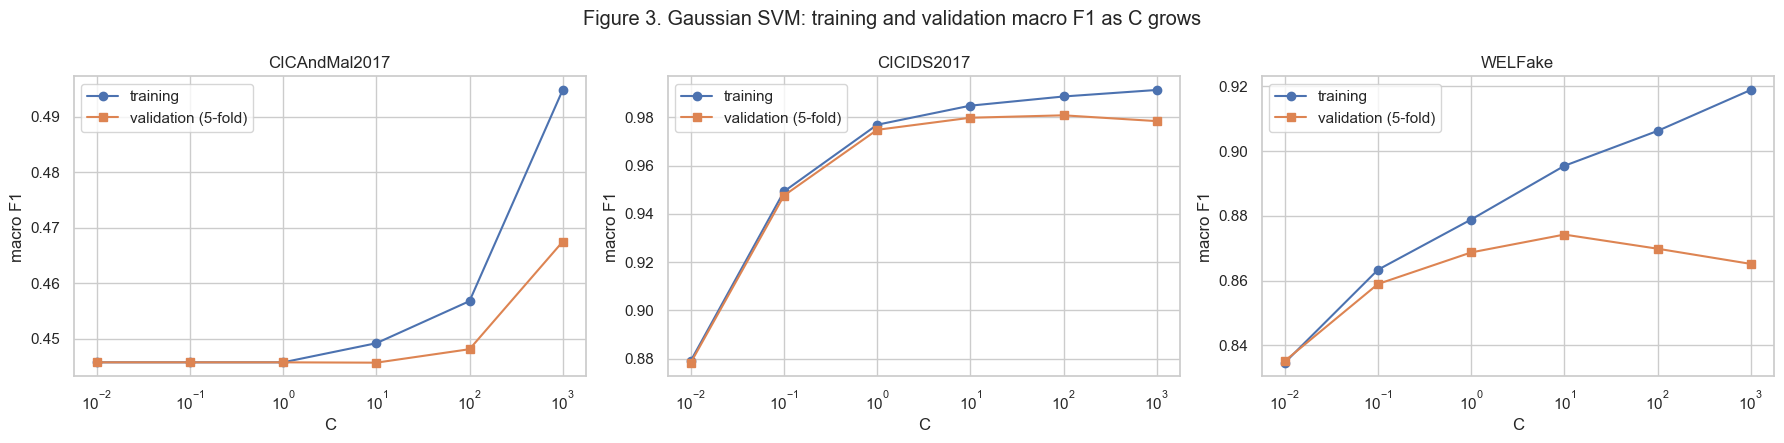

In [32]:
C_GRID = np.logspace(-2, 3, 6)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (name, s) in zip(axes, SPLITS.items()):
    X5, y5 = s["X_small"][:5000], s["y_small"][:5000]
    train_sc, val_sc = validation_curve(SVC(kernel="rbf"), X5, y5, param_name="C", param_range=C_GRID, cv=5, scoring="f1_macro")
    ax.plot(C_GRID, train_sc.mean(axis=1), "o-", label="training")
    ax.plot(C_GRID, val_sc.mean(axis=1), "s-", label="validation (5-fold)")
    ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("macro F1"); ax.set_title(name); ax.legend()
    n_sv = [len(SVC(kernel="rbf", C=c).fit(X5, y5).support_) / len(y5) for c in C_GRID]
    print(f"{name}: share of training points that are support vectors for C = {list(C_GRID)}: {np.round(n_sv, 2)}")
fig.suptitle("Figure 3. Gaussian SVM: training and validation macro F1 as C grows")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_C_curve.png", dpi=150); plt.show()

In [ ]:
TUNED = {}
for name, s in SPLITS.items():
    X5, y5 = s["X_small"][:5000], s["y_small"][:5000]
    search = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}, cv=5, scoring="f1_macro").fit(X5, y5)
    best = SVC(kernel="rbf", **search.best_params_).fit(s["X_small"], s["y_small"])
    TUNED[name] = best
    results.append({"dataset": name, "model": "Gaussian SVM, tuned (10k rows)",
                    **scores(s["y_test"], best.predict(s["X_test"]), best.decision_function(s["X_test"]))})
    print(f"{name}: best C = {search.best_params_['C']}, best gamma = {search.best_params_['gamma']}, "
          f"cross-validated macro F1 = {search.best_score_:.3f}, test macro F1 = {results[-1]['macro F1']:.3f}")
    grid = pd.DataFrame(search.cv_results_).pivot(index="param_C", columns="param_gamma", values="mean_test_score")
    print(grid.round(3), "\n")

WELFake: best C = 10, best gamma = 0.1, cross-validated macro F1 = 0.875, test macro F1 = 0.870
param_gamma  0.010   0.100   1.000   10.000
param_C                                    
0.100         0.812   0.855   0.858   0.472
1.000         0.849   0.868   0.869   0.842
10.000        0.863   0.875   0.859   0.831
100.000       0.868   0.874   0.844   0.826 



Results:
- Figure 3 shows the lesson's trade-off. As C grows, the SVM tries harder to classify every training point, so training F1 keeps rising. For WELFake, validation F1 peaks at C = 10 (0.874) and then falls (0.865 at C = 1000) while training F1 keeps climbing to 0.919. That growing gap is overfitting. For CICIDS2017 training and validation stay close, because the classes really are separable.
- The share of training points that are support vectors tells the same story. In CICIDS2017 it drops from 58% at C = 0.01 to 5% at C = 1000. Only a few points near the boundary are needed. In CICAndMal2017 it stays around 40 to 50% at every C, because the classes overlap everywhere.
- The joint search picked C = 10 with gamma = 1 for CICIDS2017 (test macro F1 0.987) and C = 10 with gamma = 0.1 for WELFake (0.870). For WELFake, a very narrow kernel (gamma 10) with a small C drops to 0.472. Each point then only influences its own tiny neighborhood, so the model cannot generalize.
- CICAndMal2017 picked the most flexible setting in the grid (C = 100, gamma = 10). That only lifts macro F1 from 0.446 to 0.504, a sign the model is chasing noise rather than a real pattern.

## 11. Using the margin to compare domains
The decision function gives each test point a signed distance from the boundary, measured in units of the margin: values above 1 or below -1 are clearly outside the margin, and values between -1 and 1 are inside it. If malicious and benign data were cleanly separable, almost all points would sit outside the margin on the correct side. The share of points inside the margin is a simple measure of how much the two classes overlap in each domain.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
margin_rows = []
for ax, (name, s) in zip(axes, SPLITS.items()):
    f = TUNED[name].decision_function(s["X_test"])
    y = s["y_test"]
    signed = np.where(y == 1, f, -f)          # positive = correct side
    margin_rows.append({"dataset": name,
                        "inside the margin": np.mean(np.abs(f) < 1),
                        "outside the margin, correct side": np.mean(signed >= 1),
                        "outside the margin, wrong side": np.mean(signed <= -1),
                        "support vectors (share of training rows)": len(TUNED[name].support_) / len(s["y_small"])})
    ax.hist(f[y == 0], bins=80, alpha=0.6, label="benign", density=True)
    ax.hist(f[y == 1], bins=80, alpha=0.6, label="malicious", density=True)
    ax.axvspan(-1, 1, color="gray", alpha=0.15, label="inside the margin")
    ax.set_xlim(-4, 4); ax.set_xlabel("decision function (distance in margin units)"); ax.set_title(name); ax.legend(fontsize=8)
fig.suptitle("Figure 4. Where the test points fall relative to the tuned Gaussian SVM's margin")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_margin_by_domain.png", dpi=150); plt.show()
pd.DataFrame(margin_rows).set_index("dataset")

This is a new way to compare the three domains:
- CICIDS2017: only 6% of test flows fall inside the margin, 94% are clearly on the correct side, and just 0.4% are clearly on the wrong side. Only 6% of training rows are support vectors. Attacks and normal traffic are well separated.
- WELFake: 29% of articles fall inside the margin and 3.5% are on the wrong side. There is a clear separation but a large gray zone.
- CICAndMal2017: 38% fall inside the margin and 13% are clearly on the wrong side. Half the training rows are support vectors. The benign and malicious histograms sit on top of each other in Figure 4.

For the research question, how separable malicious data is varies a lot by domain. A network attack like DoS leaves a strong, clean signature. Fake news leaves a moderate one. Android malware leaves almost none at the level of single flows. A shared fingerprint would need the domains to look alike, and at the margin level they clearly do not.

For a security team, the points inside the margin are the natural group to send to an analyst for review, and the size of that group differs by domain (6% vs 38%).

### 11b. Split by capture file (follow-up from Week 4)
Week 4 found that CICAndMal2017 flows from the same capture file are not independent, and suggested that flexible models could memorize individual captures. The Gaussian SVM is flexible, so I compare a random split with a split by capture file, both with 10,000 training rows.

In [39]:
s = SPLITS["CICAndMal2017"]
df = mal.reset_index(drop=True)
rows = []
for label in ["random split", "split by capture file"]:
    if label == "random split":
        tr, te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=df["malicious"])
    else:
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(df, groups=df["file"]))
    tr = np.random.RandomState(SEED).choice(tr, 10000, replace=False)
    te = np.random.RandomState(SEED).choice(te, 20000, replace=False)
    scaler = StandardScaler().fit(df.loc[tr, NET])
    model = SVC(kernel="rbf", C=TUNED["CICAndMal2017"].C, gamma=TUNED["CICAndMal2017"].gamma).fit(scaler.transform(df.loc[tr, NET]), df.loc[tr, "malicious"])
    Xte = scaler.transform(df.loc[te, NET])
    rows.append({"split": label, **scores(df.loc[te, "malicious"], model.predict(Xte), model.decision_function(Xte))})
pd.DataFrame(rows)

,split,accuracy,macro F1,ROC AUC
0,random split,0.758,0.500,0.544
1,split by capture file,0.768,0.505,0.542


Even with the flexible Gaussian SVM, splitting by capture file gives the same result as a random split (AUC 0.542 vs 0.544). The model is not memorizing individual captures, because with these 7 flow features there is nothing distinctive to memorize. Week 6 will repeat this check with random forests, which can memorize much more detail.

## 12. Summary

macro F1                          ROC AUC  \
dataset                        CICAndMal2017 CICIDS2017 WELFake CICAndMal2017   
model                                                                           
Gaussian SVM (10k rows)                0.443      0.978   0.866         0.532   
Gaussian SVM, tuned (10k rows)         0.500      0.987   0.870         0.544   
Linear SVM (10k rows)                  0.443      0.895   0.828         0.527   
Linear SVM (all rows)                  0.443      0.897   0.828         0.533   
Logistic (10k rows)                    0.443      0.894   0.828         0.530   
Polynomial SVM (10k rows)              0.443      0.945   0.795         0.475   

                                                   
dataset                        CICIDS2017 WELFake  
model                                              
Gaussian SVM (10k rows)             0.994   0.936  
Gaussian SVM, tuned (10k rows)      0.998   0.937  
Linear SVM (10k rows)               0.949   0.896  
Linear SVM (all rows)               0.950   0.896  
Logistic (10k rows)                 0.941   0.896  
Polynomial SVM (10k rows)           0.960   0.896

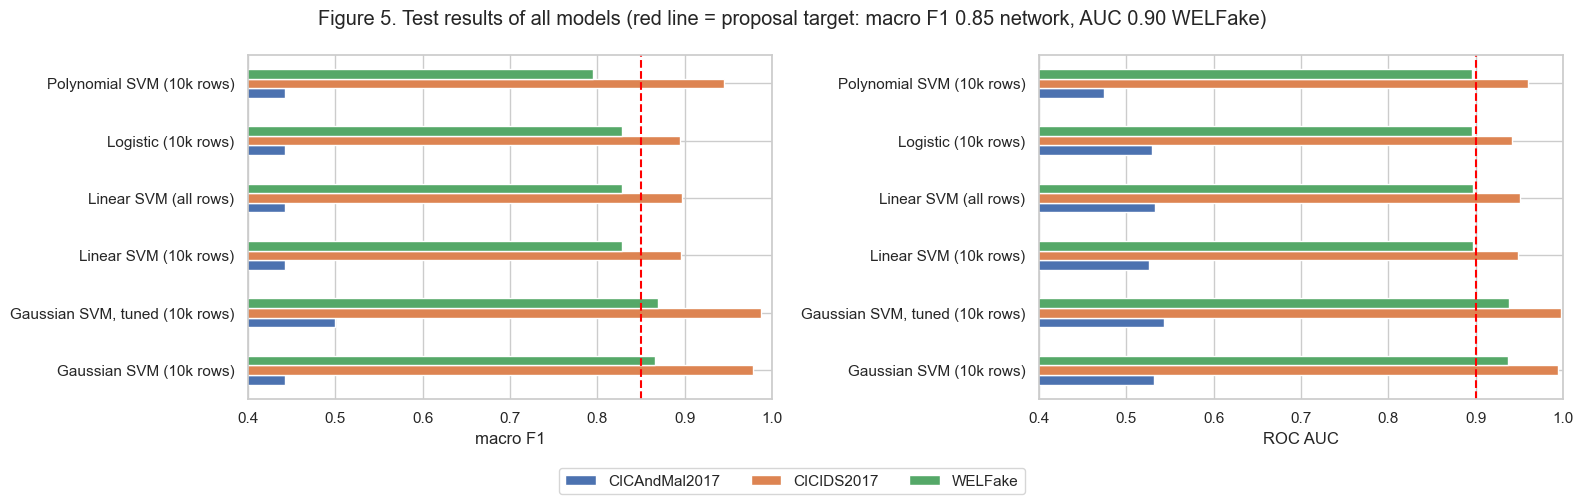

In [42]:
summary = pd.DataFrame(results)
display(summary.pivot(index="model", columns="dataset", values=["macro F1", "ROC AUC"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric, target in [(axes[0], "macro F1", 0.85), (axes[1], "ROC AUC", 0.90)]:
    summary.pivot(index="model", columns="dataset", values=metric).plot.barh(ax=ax, legend=False)
    ax.axvline(target, color="red", ls="--"); ax.set_xlim(0.4, 1); ax.set_xlabel(metric); ax.set_ylabel("")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3)
fig.suptitle("Figure 5. Test results of all models (red line = proposal target: macro F1 0.85 network, AUC 0.90 WELFake)")
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.savefig(FIG_DIR / "fig5_summary.png", dpi=150); plt.show()

Week 5 conclusions:
1. The Gaussian (RBF) SVM is the best model so far: CICIDS2017 macro F1 0.987 (target 0.85) and WELFake AUC 0.937 (target 0.90), both using only 10,000 training rows.
2. A linear SVM behaves almost the same as logistic regression. The kernel is what makes the difference, by allowing curved boundaries.
3. Feature scaling is essential for the Gaussian kernel: with raw units CICIDS2017 dropped to 50% accuracy.
4. C and gamma control overfitting. A large C and narrow kernel fit the training data more closely but generalize worse, which is clearest in WELFake.
5. CICAndMal2017 is still not separable with these features (macro F1 0.50 at best). The margin analysis shows why: 38% of flows sit inside the margin and half the training data are support vectors.
6. The share of points inside the margin (6%, 29%, 38%) gives a simple cross-domain comparison. How cleanly malicious data separates from benign data depends strongly on the domain.

## 13. Think About It

1. Is it possible to be sure that the margin on one side equals the margin on the other side? Yes. If one side had more room, the hyperplane could be shifted toward that side, which would make the smaller margin bigger. So the hyperplane with the largest margin always sits in the middle. Section 2 confirms this: 1.016 on both sides.

2. Polynomial kernel in 2 dimensions with c = 0: (x.z)^2 = x1^2 z1^2 + 2 x1x2 z1z2 + x2^2 z2^2, which is the inner product of (x1^2, x1x2, x2x1, x2^2) with (z1^2, z1z2, z2z1, z2^2). Combining the two middle terms gives the 3-dimensional version (x1^2, sqrt(2) x1x2, x2^2). Section 3b checks this numerically.

3. How can we tell the Gaussian kernel is not just x.z? K(x, x) is always 1, but x.x changes with the length of x. Multiplying x by 10 multiplies x.z by 10, but makes K almost 0 (section 3c). It is not easy to find other vectors whose inner product gives K. They would need infinitely many dimensions. But the kernel matrix has no negative eigenvalues, which is what lets the SVM treat it as an inner product.

4. Why does a large margin help with new data? If every training point is far from the boundary, a new point that is slightly different from the training points will most likely still land on the same side. A boundary that only just squeezes past the training points will misclassify new points that land slightly differently. In my data, CICIDS2017 has a wide, clean margin (only 6% of test points inside it) and very high test accuracy.

5. How does a kernel help separate data that cannot be split with a straight line? The kernel acts like adding new features (squares, products, or infinitely many for the Gaussian), without computing them. A flat hyperplane in that bigger space becomes a curved boundary in the original space. Figure 2 shows this: the Gaussian kernel draws closed curves around the attack flows in CICIDS2017, which a straight line cannot do.

6. When is it better to allow a few misclassified points for a larger margin? When those few points are noise, mislabeled or rare oddities, forcing the boundary around them makes it bend and narrows the margin for everyone else. A smaller C allows those mistakes and keeps a wider, smoother boundary. In WELFake, validation F1 was best at C = 10 and dropped at C = 1000, even though training F1 kept rising. Some articles look like the other class, and chasing them hurts on new data.

## 14. Notes for the Milestone One write-up
| Rubric item | What I did |
|---|---|
| Avoiding overfitting | The C parameter (margin vs training errors), training vs validation curves for C, 5-fold cross-validation for C and gamma, 80/20 train/test split, and a split by capture file for CICAndMal2017 |
| Metrics | Accuracy, macro F1 and ROC AUC (using the decision function), share of points inside the margin, share of support vectors |
| Hyperparameter tuning | C from 0.01 to 1000, and a grid of C (0.1 to 100) by gamma (0.01 to 10) for the Gaussian kernel |
| How EDA helped | Week 4 showed the classes overlap heavily in CICAndMal2017 and the features need scaling, which explained the SVM results here |